In [2]:
import pandas as pd
import numpy as np
from basin import *
from MultiAgent_DQ import *
import sys
sys.path.append('../')
from utils import *
from typing import Dict, Tuple

In [2]:
# Parameters
t = 1
s = 0
r = 0.7
p = 0.2
epsilon = 0.1
d = 0.6
alpha = 0.3
bound = 1 / (1 - d)

In [3]:

def trim_q_by_strategy(q1, q2, s1, s2):
    """
    Trim q1 and q2 sequences based on their respective initial strategy orderings.
    Both sequences are cut to the same length, determined by when *either* violates
    its initial ordering — whichever lasts longer determines the trim point.
    
    Parameters
    ----------
    q1, q2 : pd.DataFrame or np.ndarray
        Time × features (Q-values). Must have same length along time axis.
    s1, s2 : str
        Strategies for q1 and q2, each one of {"AD","GT","AGT","AC"}.
        
    Returns
    -------
    q1_trimmed, q2_trimmed : same type as input
        Trimmed sequences up to the last timestep where both maintain initial ordering.
    """
    
    # Convert to numpy if DataFrames
    q1_arr = q1.values if hasattr(q1, "values") else np.asarray(q1)
    q2_arr = q2.values if hasattr(q2, "values") else np.asarray(q2)
    
    def ordering_sign(Q, strategy):
        """
        Compute sign of (defect - coop) according to strategy from a 2x2 Q-matrix or row pair.
        Positive sign → defect > coop, Negative → coop > defect.
        """
        delta = Q[1] - Q[0]
        if strategy in ["GT", "AC"]:
            delta = -delta
        return np.sign(delta)
    
    def valid_length(Q, strategy):
        """Return how long ordering stays consistent with the initial."""
        # Use first two timesteps as reference
        ref_sign = ordering_sign(Q[:2], strategy)
        last_valid_idx = 1
        for t in range(1, Q.shape[0]):
            cur_sign = ordering_sign(Q[t-1:t+1], strategy)
            if np.all(cur_sign == ref_sign):
                last_valid_idx = t
            else:
                break
        return last_valid_idx + 1  # inclusive index
    
    len1 = valid_length(q1_arr, s1)
    len2 = valid_length(q2_arr, s2)
    
    # Cut based on whichever lasts longer
    cut_len = min(len1, len2) 
    
    if hasattr(q1, "iloc"):
        return q1.iloc[:cut_len], q2.iloc[:cut_len]
    else:
        return q1_arr[:cut_len], q2_arr[:cut_len]


Using seed: 550069866
Running pair: (AD, AD)
DEBUG: Vector field parameters
epsilon = 0.1
func1 = QvaluesADvsAD
func2 = QvaluesADvsAD

Q1 from QvaluesADvsAD: [0.584625 0.379625]
Q2 from QvaluesADvsAD: [0.584625 0.379625]

Vector field TARGET: (0.2050, 0.2050)

Trajectory endpoint:
  Player 1 (x): 0.2051
  Player 2 (y): 0.2053
Running pair: (AD, GT)
DEBUG: Vector field parameters
epsilon = 0.1
func1 = QvaluesGTvsGT
func2 = QvaluesADvsAD

Q1 from QvaluesGTvsGT: [1.30682609 1.56943478]
Q2 from QvaluesADvsAD: [0.584625 0.379625]

Vector field TARGET: (-0.2626, 0.2050)

Trajectory endpoint:
  Player 1 (x): 0.0436
  Player 2 (y): 0.0484
Running pair: (AD, AGT)
DEBUG: Vector field parameters
epsilon = 0.1
func1 = QvaluesADvsAGT
func2 = QvaluesADvsAD

Q1 from QvaluesADvsAGT: [1.62809153 1.40219085]
Q2 from QvaluesADvsAD: [0.584625 0.379625]

Vector field TARGET: (0.2259, 0.2050)

Trajectory endpoint:
  Player 1 (x): 0.2076
  Player 2 (y): 0.4053
Running pair: (AD, AC)
DEBUG: Vector field param

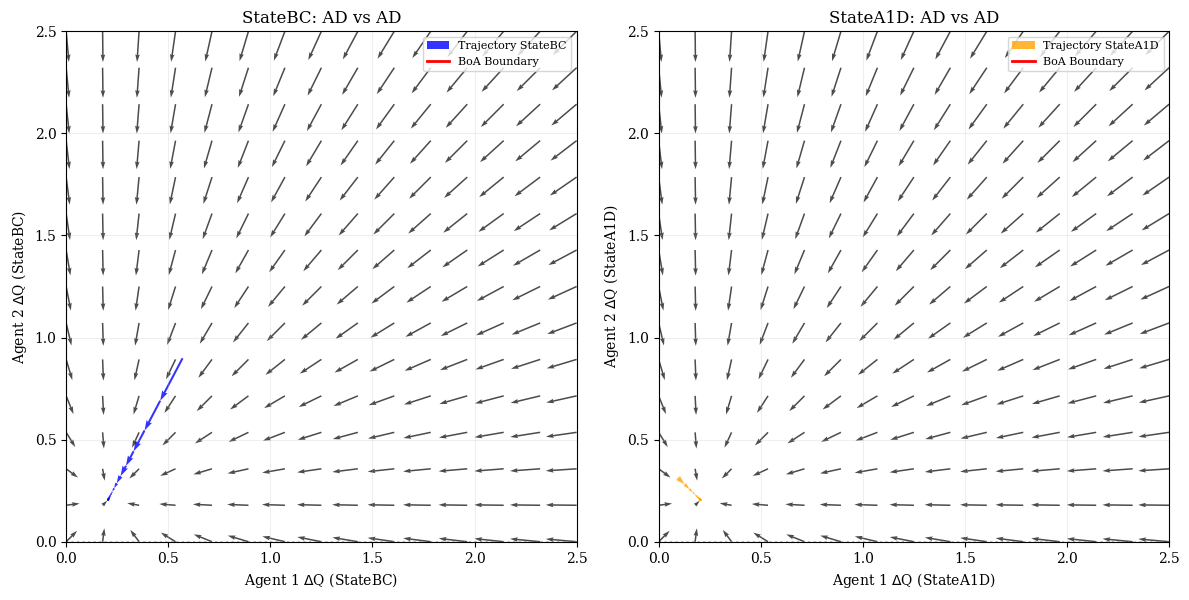

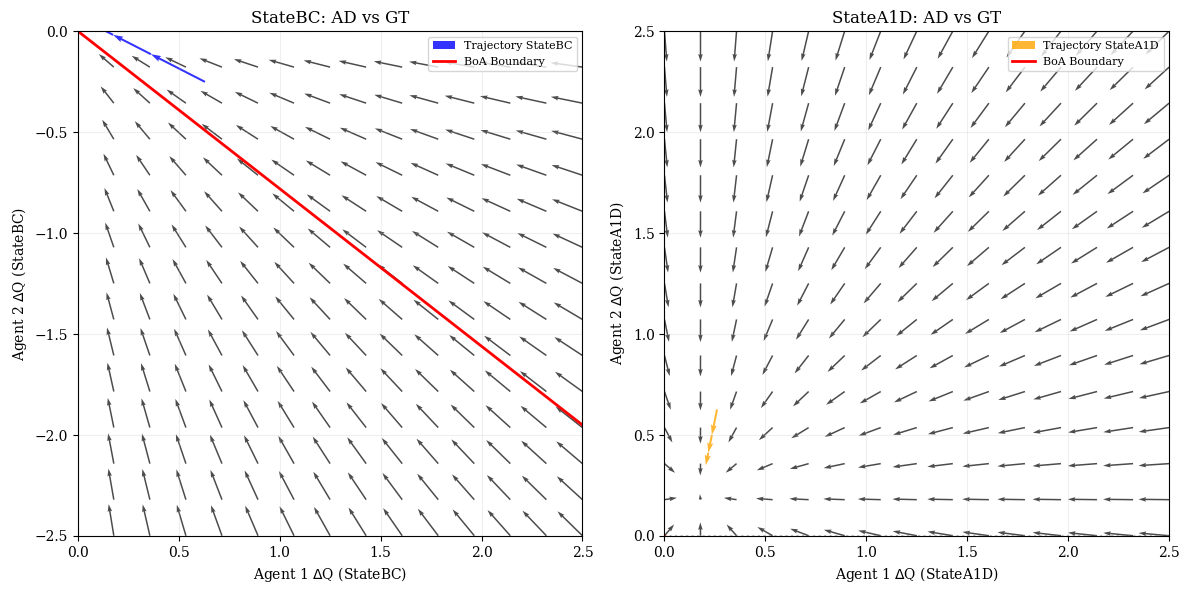

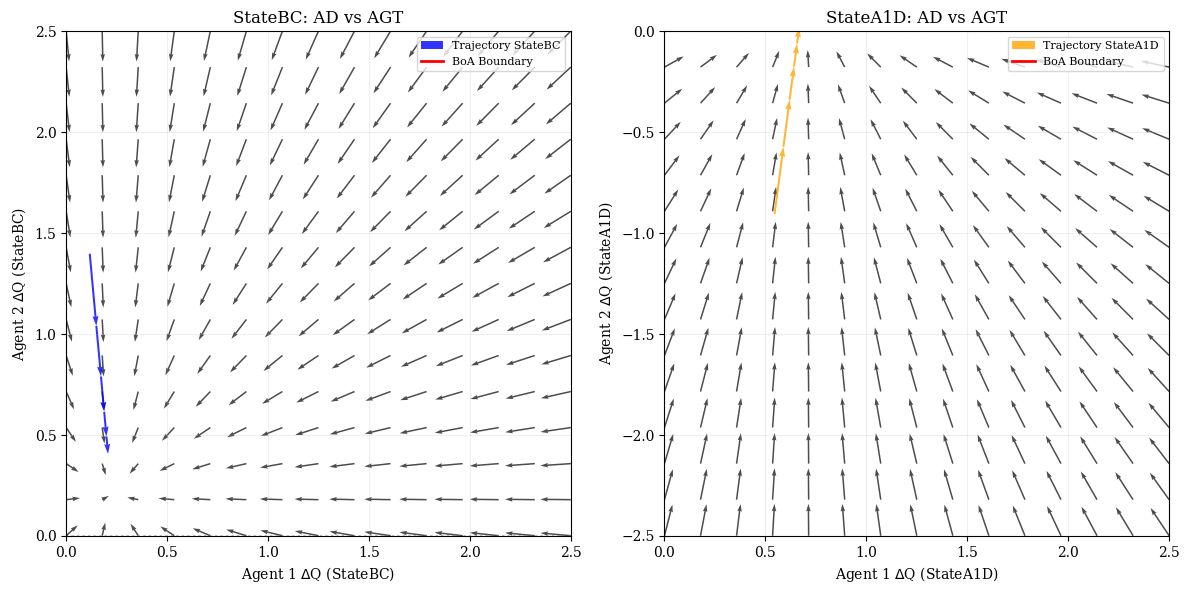

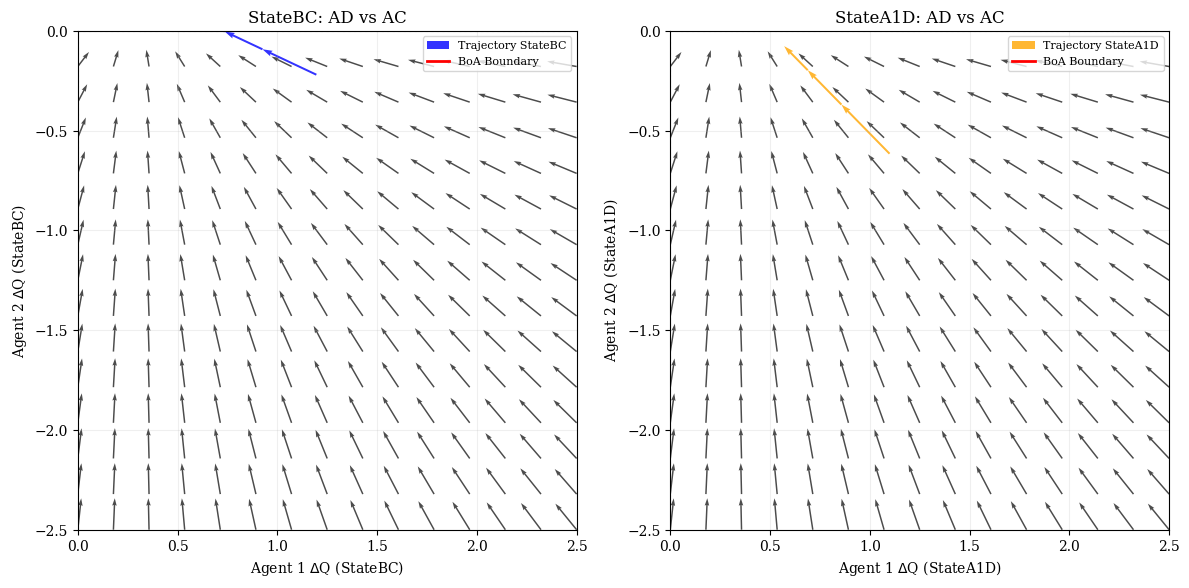

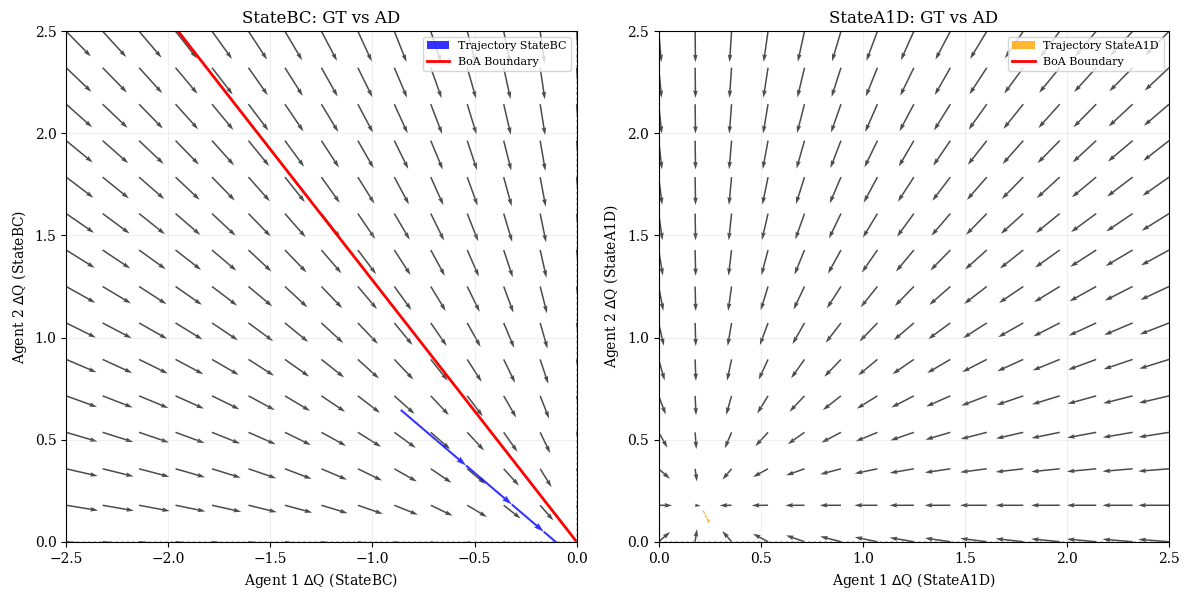

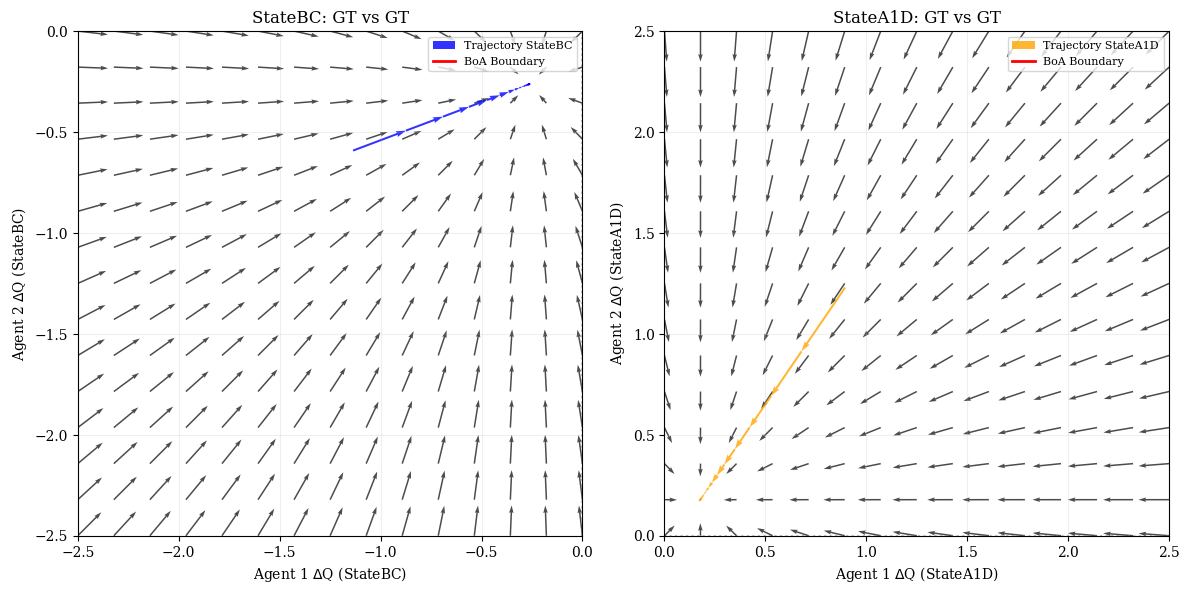

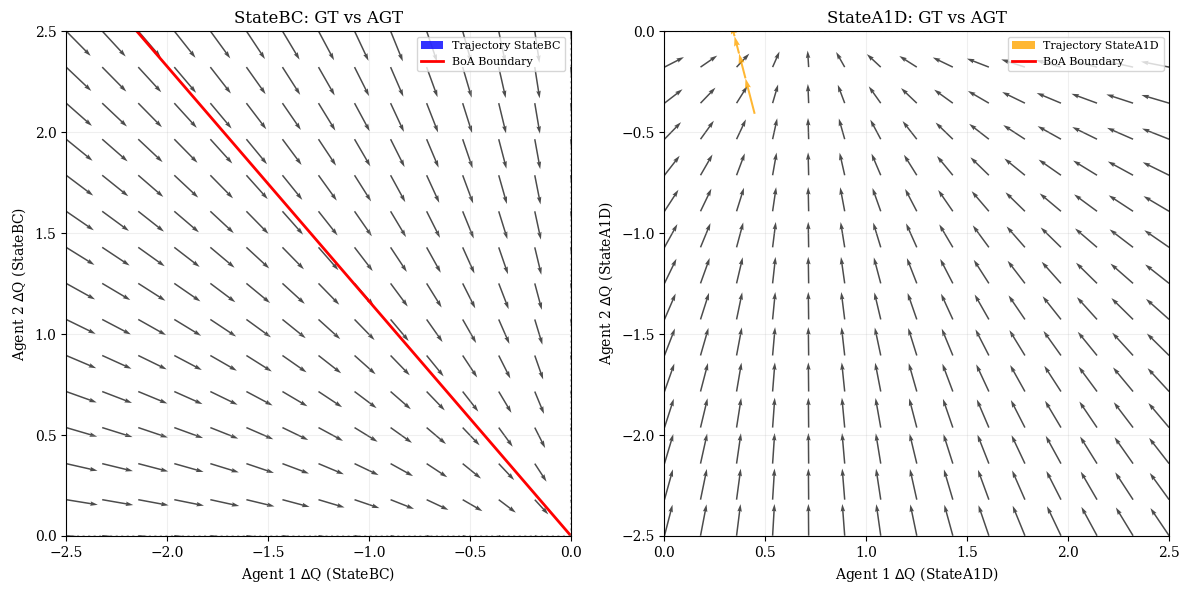

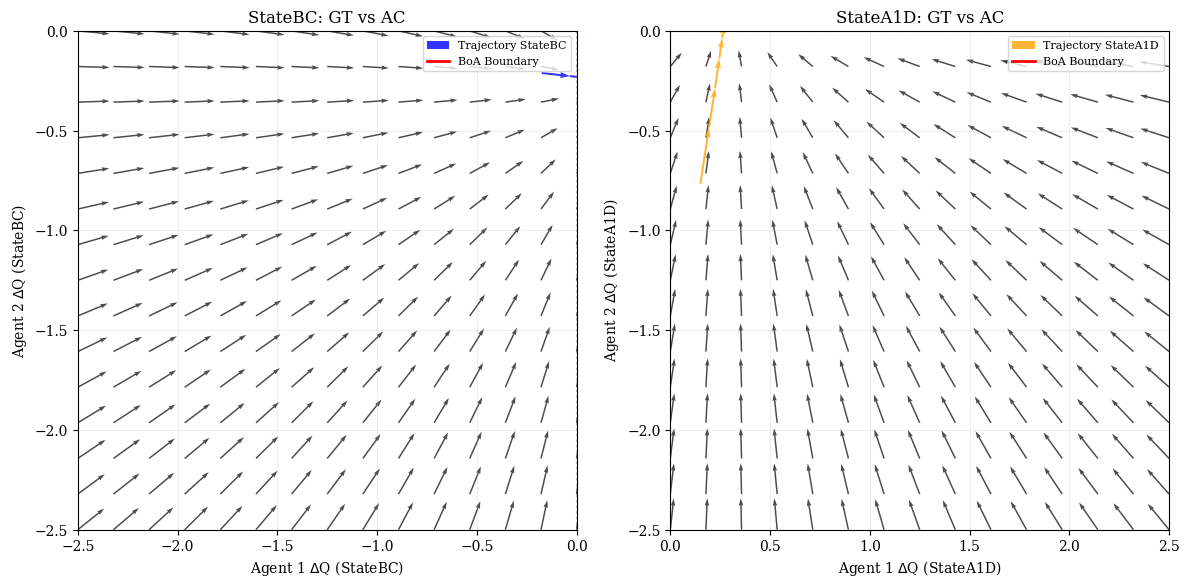

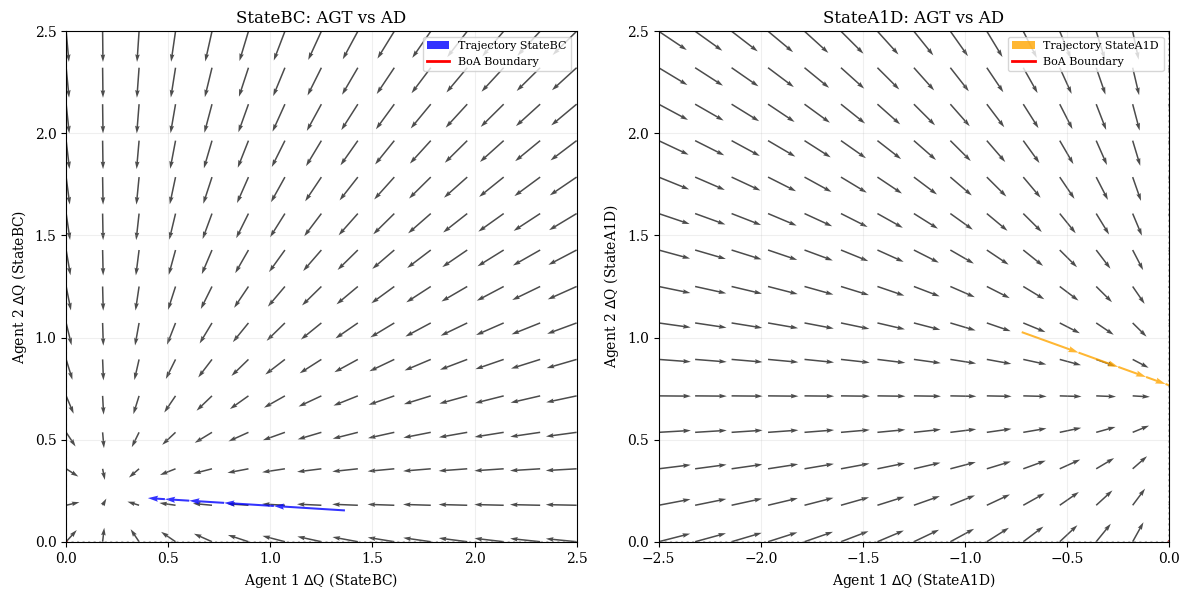

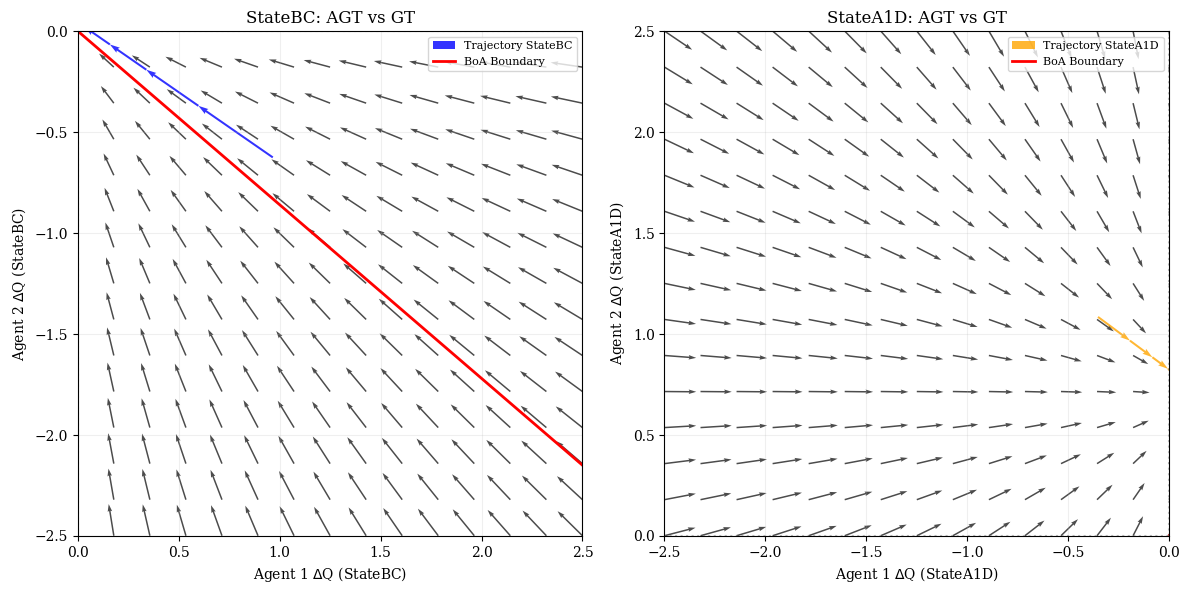

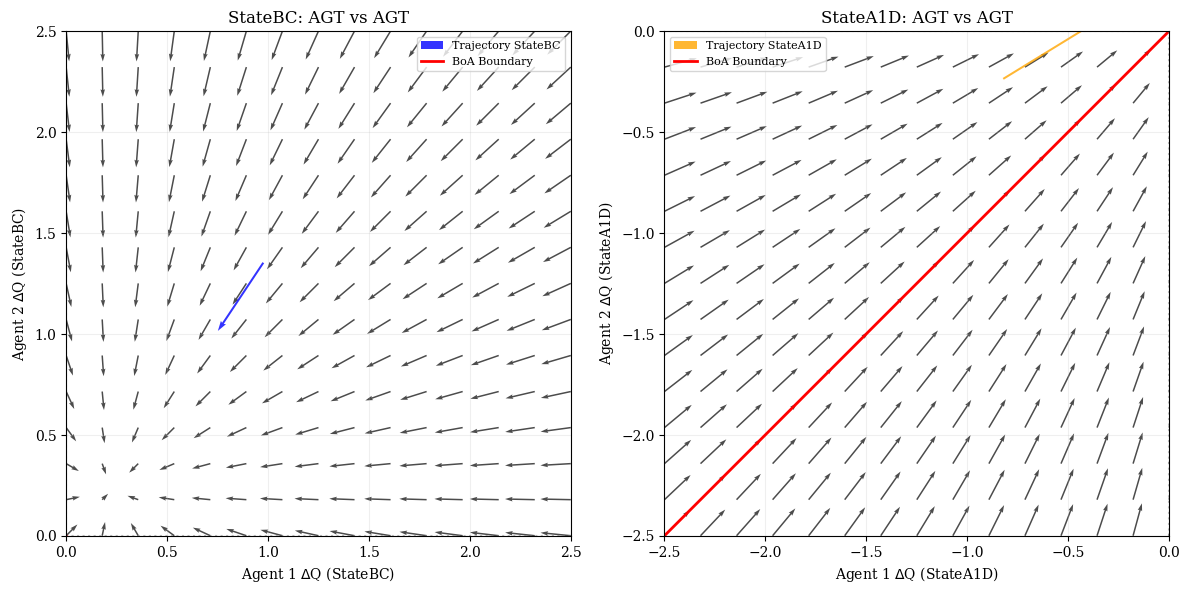

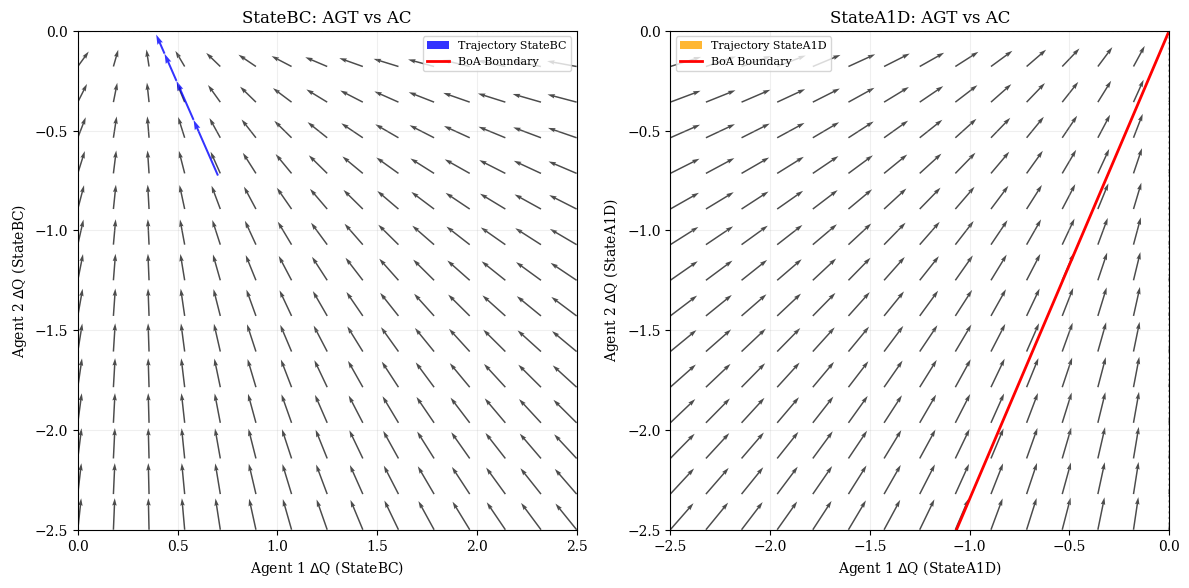

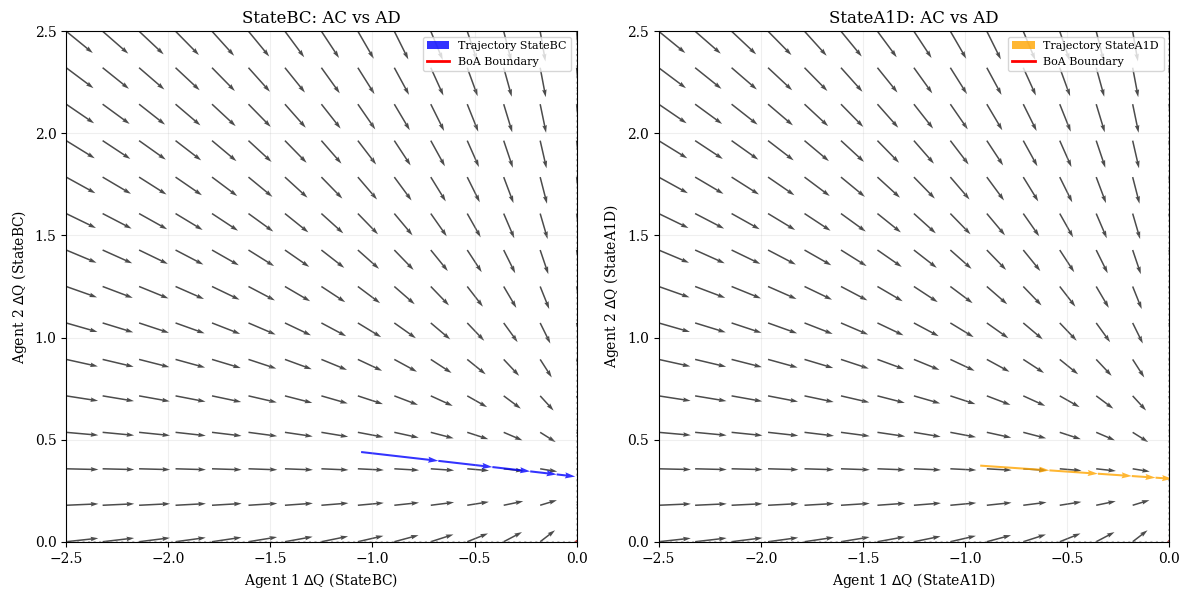

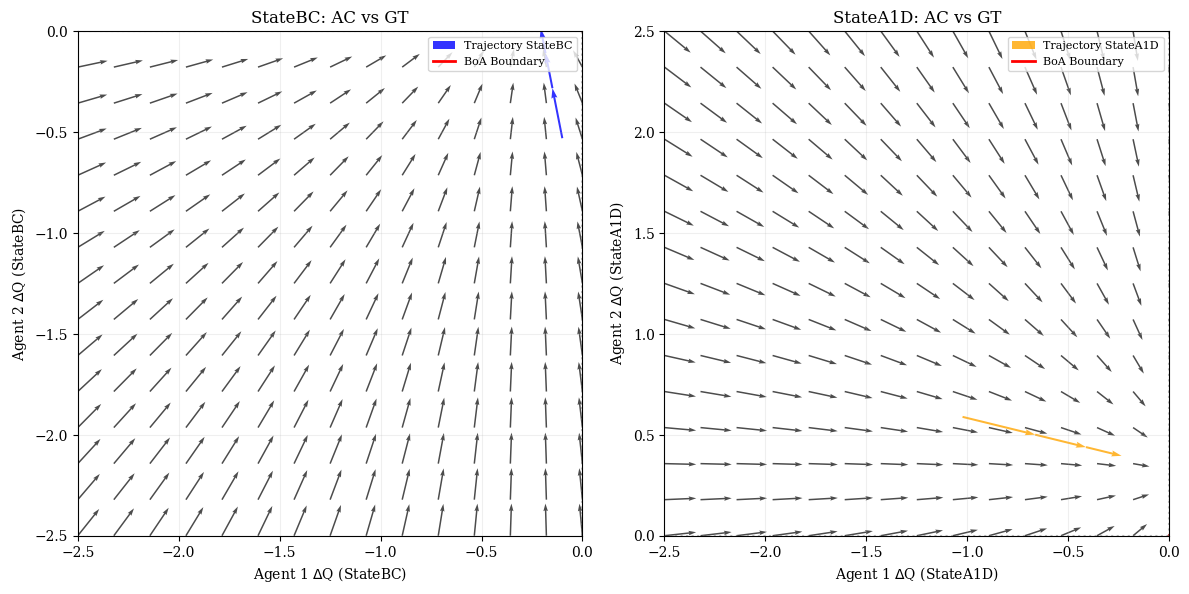

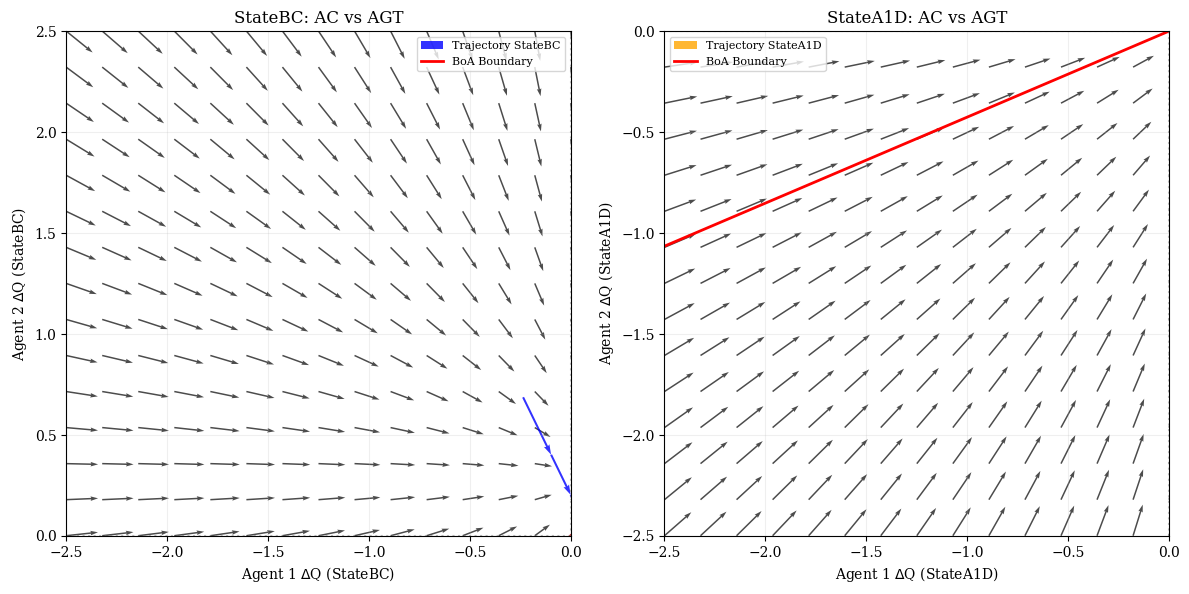

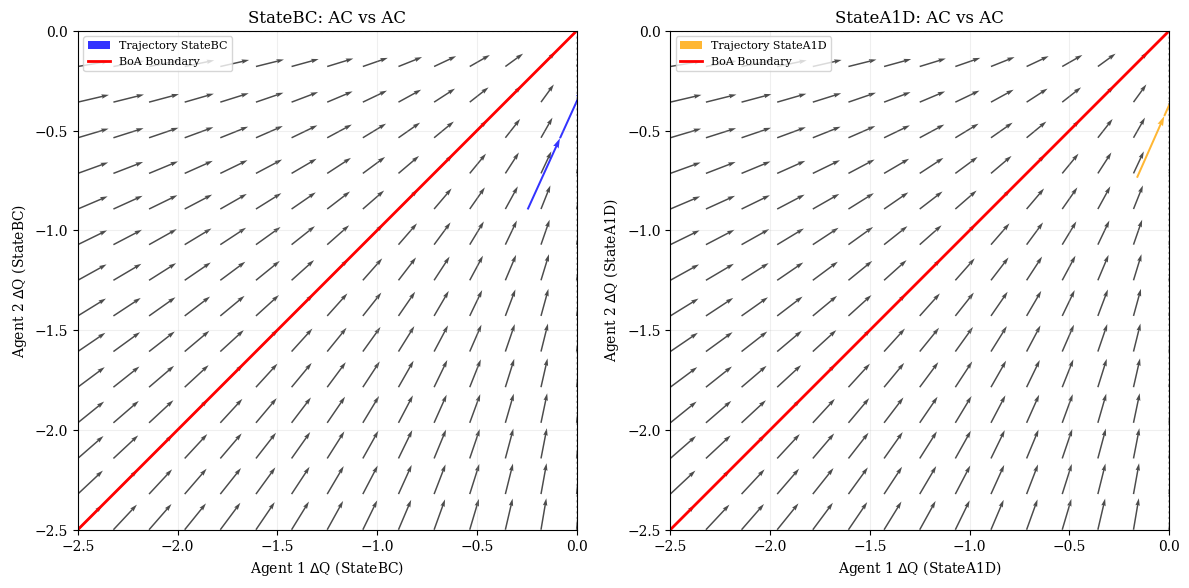

In [5]:
# Strategy pairs
strategy_pairs = [
    ("AD","AD"), ("AD","GT"), ("AD","AGT"), ("AD","AC"),
    ("GT","AD"), ("GT","GT"), ("GT","AGT"), ("GT","AC"),
    ("AGT","AD"), ("AGT","GT"), ("AGT","AGT"), ("AGT","AC"),
    ("AC","AD"), ("AC","GT"), ("AC","AGT"), 
    ("AC","AC")
]
stop_when_cross = True
# Map opponent strategy to function
func_map = {
    "AD": QvaluesADvsAD,
    "GT": QvaluesGTvsGT,
    "AGT": QvaluesADvsAGT,
    "AC": QvaluesADvsAC
}
randomseeds = np.random.randint(1, 1020131031, size=1)  # 5 is exclusive

for seed in randomseeds:
    np.random.seed(seed)
    print(f"Using seed: {seed}")
    for s1, s2 in strategy_pairs:
        print(f"Running pair: ({s1}, {s2})")

        # Initialize algorithm with fixed strategy pair
        algo = Algorithm(
            e=epsilon, lambda_val=0, alpha=alpha, delta=d,
            init_mode='fixed', tolerance=1e-10, 
            M=5, strategy1=s1, strategy2=s2,
            t=t, r=r, p=p, s=s,  # Pass payoff parameters
            verbose=False
        )

        # Run the algorithm
        q1_history_per_sample_algo, q2_history_per_sample_algo, batch_times_algo, timeout_out, timeout_vi = algo.run()

        # Pick a sample
        exp = np.random.randint(0, 5)
        q1 = convert_dict_to_mean_df(q1_history_per_sample_algo, mean=False)[exp]
        q2 = convert_dict_to_mean_df(q2_history_per_sample_algo, mean=False)[exp]
        if stop_when_cross:
            q1, q2 = trim_q_by_strategy(q1, q2, s1, s2)
        func1 = func_map[s2]  # x-component uses opponent strategy s2
        func2 = func_map[s1]  # y-component uses same opponent strategy
        #check if the ordering changes here input (q1, q2, s1, s2)
        # Plot vector field with strategy information
        plotter = VectorFieldAutomatic(
            q1=q1, q2=q2,
            t=t, r=r, p=p, s=s, epsilon=epsilon, d=d,
            func1=func1,
            func2=func2,
            strategy1=s1,    # Add strategy1
            strategy2=s2,    # Add strategy2
            alpha=alpha,
            density=15,
            show_trajectory=True,
            show_basin=True
        )
        
                    
                    
        plotter.plot(show_all_quadrants=False)
        # Add this debug cell after the plotter is created
        print("="*60)
        print("DEBUG: Vector field parameters")
        print(f"epsilon = {epsilon}")
        print(f"func1 = {func1.__name__}")
        print(f"func2 = {func2.__name__}")

        # Compute the actual target
        Q1_debug = func1(t, r, p, s, epsilon, d)[0]  # State 0
        Q2_debug = func2(t, r, p, s, epsilon, d)[0]  # State 0
        dQx_debug = Q1_debug[0] - Q1_debug[1]
        dQy_debug = Q2_debug[0] - Q2_debug[1]

        print(f"\nQ1 from {func1.__name__}: {Q1_debug}")
        print(f"Q2 from {func2.__name__}: {Q2_debug}")
        print(f"\nVector field TARGET: ({dQx_debug:.4f}, {dQy_debug:.4f})")

        # Check trajectory endpoint
        print(f"\nTrajectory endpoint:")
        print(f"  Player 1 (x): {q1['StateBC'].iloc[-1]:.4f}")
        print(f"  Player 2 (y): {q2['StateBC'].iloc[-1]:.4f}")
        print("="*60)
        
    





In [3]:
def compute_conditional_probabilities(pi_ADGT: float) -> Dict[str, float]:
    """
    Compute conditional probabilities P(GT,GT | S1,S2) for all 16 initial configurations.
    
    Args:
        pi_ADGT: Basin of attraction probability from (AD, GT) configuration
    
    Returns:
        Dictionary mapping configuration names to conditional probabilities
    """
    probs = {}
    
    # Item 1: Equilibria (2 configurations)
    probs['GT,GT'] = 1/16
    probs['AD,AD'] = 0.0
    
    # Item 2: Deterministic convergence to AD (6 configurations)
    probs['AD,AGT'] = 0.0
    probs['AGT,AD'] = 0.0
    probs['AC,AD'] = 0.0
    probs['AD,AC'] = 0.0
    probs['AGT,AGT'] = 0.0
    
    # Item 3: Single basin (2 configurations)
    probs['AD,GT'] = (1/16) * pi_ADGT
    probs['GT,AD'] = (1/16) * pi_ADGT
    
    # Item 4: Symmetric indifference (2 configurations)
    probs['GT,AC'] = (1/32) * (1 + pi_ADGT)
    probs['AC,GT'] = (1/32) * (1 + pi_ADGT)
    
    # Item 5: Multi-step configurations (5 configurations)
    # These cannot be computed exactly, so we return None
    probs['AGT,GT'] = None  # Lower: 0, Upper: 1/16
    probs['GT,AGT'] = None  # Lower: 0, Upper: 1/16
    probs['AC,AGT'] = None  # Lower: 0, Upper: 1/16
    probs['AGT,AC'] = None  # Lower: 0, Upper: 1/16
    probs['AC,AC'] = None   # Lower: 0, Upper: 1/16
    
    return probs


def compute_aggregate_probability(pi_ADGT: float, 
                                  return_bounds: bool = True) -> Tuple[float, float]:
    """
    Compute the aggregate probability P(GT,GT) with bounds.
    
    The exact value includes:
    - 1/16 from (GT,GT) equilibrium
    - 2/16 * pi_ADGT from (AD,GT) and (GT,AD)
    - 2/32 * (1 + pi_ADGT) from (GT,AC) and (AC,GT)
    
    Plus unknown contributions from 5 multi-step configurations.
    
    Args:
        pi_ADGT: Basin of attraction probability from (AD, GT) configuration
        return_bounds: If True, return (lower_bound, upper_bound), 
                      otherwise return point estimate (lower bound)
    
    Returns:
        If return_bounds=True: (lower_bound, upper_bound)
        If return_bounds=False: lower_bound only (assuming multi-step = 0)
    """
    # Known contributions
    equilibrium_contrib = 1/16  # (GT,GT)
    single_basin_contrib = (2/16) * pi_ADGT  # (AD,GT) and (GT,AD)
    symmetric_contrib = (2/32) * (1 + pi_ADGT)  # (GT,AC) and (AC,GT)
    
    # Simplify symmetric contribution
    # (2/32) * (1 + pi_ADGT) = (1/16) * (1 + pi_ADGT) = 1/16 + (1/16)*pi_ADGT
    symmetric_contrib = (1/16) + (1/16) * pi_ADGT
    
    # Known total
    # 1/16 + 2/16*pi_ADGT + 1/16 + 1/16*pi_ADGT = 2/16 + 3/16*pi_ADGT
    known_total = equilibrium_contrib + single_basin_contrib + symmetric_contrib
    
    # Bounds for multi-step configurations (5 configs, each contributing [0, 1/16])
    multi_step_lower = 0.0
    multi_step_upper = 5 * (1/16)
    
    lower_bound = known_total + multi_step_lower
    upper_bound = known_total + multi_step_upper
    
    # Simplify bounds
    # Lower: 2/16 + 3/16*pi_ADGT = (1/16)(2 + 3*pi_ADGT)
    # Upper: 2/16 + 3/16*pi_ADGT + 5/16 = (1/16)(7 + 3*pi_ADGT)
    lower_bound = (1/16) * (2 + 3 * pi_ADGT)
    upper_bound = (1/16) * (7 + 3 * pi_ADGT)
    
    if return_bounds:
        return (lower_bound, upper_bound)
    else:
        return lower_bound


def print_detailed_results(pi_ADGT: float):
    """
    Print detailed breakdown of all probabilities and bounds.
    
    Args:
        pi_ADGT: Basin of attraction probability from (AD, GT) configuration
    """
    print("=" * 70)
    print("REFINED BASIN OF ATTRACTION BOUNDS VIA TRANSITION ANALYSIS")
    print("=" * 70)
    print(f"\nInput parameter: π_ADGT = {pi_ADGT:.6f}")
    print("\n" + "-" * 70)
    print("CONDITIONAL PROBABILITIES P(GT,GT | S1,S2)")
    print("-" * 70)
    
    probs = compute_conditional_probabilities(pi_ADGT)
    
    print("\n1. Equilibria (2 configurations):")
    print(f"   P(GT,GT | GT,GT) = {probs['GT,GT']:.6f}")
    print(f"   P(GT,GT | AD,AD) = {probs['AD,AD']:.6f}")
    
    print("\n2. Deterministic convergence to AD (6 configurations):")
    print(f"   P(GT,GT | AD,AGT) = {probs['AD,AGT']:.6f}")
    print(f"   P(GT,GT | AGT,AD) = {probs['AGT,AD']:.6f}")
    print(f"   P(GT,GT | AC,AD)  = {probs['AC,AD']:.6f}")
    print(f"   P(GT,GT | AD,AC)  = {probs['AD,AC']:.6f}")
    print(f"   P(GT,GT | AGT,AGT) = {probs['AGT,AGT']:.6f}")
    
    print("\n3. Single basin (2 configurations):")
    print(f"   P(GT,GT | AD,GT) = {probs['AD,GT']:.6f}")
    print(f"   P(GT,GT | GT,AD) = {probs['GT,AD']:.6f}")
    
    print("\n4. Symmetric indifference (2 configurations):")
    print(f"   P(GT,GT | GT,AC) = {probs['GT,AC']:.6f}")
    print(f"   P(GT,GT | AC,GT) = {probs['AC,GT']:.6f}")
    
    print("\n5. Multi-step configurations (5 configurations):")
    print(f"   P(GT,GT | AGT,GT) ∈ (0, {1/16:.6f})")
    print(f"   P(GT,GT | GT,AGT) ∈ (0, {1/16:.6f})")
    print(f"   P(GT,GT | AC,AGT)  ∈ (0, {1/16:.6f})")
    print(f"   P(GT,GT | AGT,AC)  ∈ (0, {1/16:.6f})")
    print(f"   P(GT,GT | AC,AC)   ∈ (0, {1/16:.6f})")
    
    print("\n" + "-" * 70)
    print("AGGREGATE PROBABILITY BOUNDS")
    print("-" * 70)
    
    lower, upper = compute_aggregate_probability(pi_ADGT, return_bounds=True)
    
    print(f"\nLower bound: P(GT,GT) ≥ {lower:.6f}")
    print(f"Upper bound: P(GT,GT) ≤ {upper:.6f}")
    print(f"\nExpected range: [{lower:.6f}, {upper:.6f}]")
    print(f"Range width: {upper - lower:.6f}")
    
    # Compute contributions
    print("\n" + "-" * 70)
    print("CONTRIBUTION BREAKDOWN (for lower bound)")
    print("-" * 70)
    
    equilibrium_contrib = 1/16
    single_basin_contrib = (2/16) * pi_ADGT
    symmetric_contrib = (1/16) * (1 + pi_ADGT)
    
    print(f"\nEquilibrium (GT,GT):              {equilibrium_contrib:.6f}")
    print(f"Single basin configs:              {single_basin_contrib:.6f}")
    print(f"Symmetric indifference configs:    {symmetric_contrib:.6f}")
    print(f"Multi-step configs (lower bound):  {0:.6f}")
    print(f"{'─' * 50}")
    print(f"Total (lower bound):               {lower:.6f}")
    
    print("\n" + "=" * 70)

In [4]:
print("Payoffs R = 0.7 and P = 0.2")
pi_ADGT = theoretical_P_AD_from_ADGT(
    t=1.0, r=0.7, p=0.2, s=0.0, epsilon=0.1, d=0.6, state_idx=0
)
print_detailed_results(pi_ADGT)
# Example 4: Computing with specific game parameters
print("\n\n" + "=" * 70)
print("Payoffs R = 0.8 and P = 0.5")
pi_ADGT = theoretical_P_AD_from_ADGT(
    t=1.0, r=0.8, p=0.5, s=0.0, epsilon=0.1, d=0.6, state_idx=0
)
print_detailed_results(pi_ADGT)

Payoffs R = 0.7 and P = 0.2
REFINED BASIN OF ATTRACTION BOUNDS VIA TRANSITION ANALYSIS

Input parameter: π_ADGT = 0.390315

----------------------------------------------------------------------
CONDITIONAL PROBABILITIES P(GT,GT | S1,S2)
----------------------------------------------------------------------

1. Equilibria (2 configurations):
   P(GT,GT | GT,GT) = 0.062500
   P(GT,GT | AD,AD) = 0.000000

2. Deterministic convergence to AD (6 configurations):
   P(GT,GT | AD,AGT) = 0.000000
   P(GT,GT | AGT,AD) = 0.000000
   P(GT,GT | AC,AD)  = 0.000000
   P(GT,GT | AD,AC)  = 0.000000
   P(GT,GT | AGT,AGT) = 0.000000

3. Single basin (2 configurations):
   P(GT,GT | AD,GT) = 0.024395
   P(GT,GT | GT,AD) = 0.024395

4. Symmetric indifference (2 configurations):
   P(GT,GT | GT,AC) = 0.043447
   P(GT,GT | AC,GT) = 0.043447

5. Multi-step configurations (5 configurations):
   P(GT,GT | AGT,GT) ∈ (0, 0.062500)
   P(GT,GT | GT,AGT) ∈ (0, 0.062500)
   P(GT,GT | AC,AGT)  ∈ (0, 0.062500)
   P(GT

In [ ]:
#ORGANIZE THE DESCRIPTION:
#BBoA = BoundaryBasinOfAttraction
#first you plot ADAD and then GTGT #equilibria
#plot two side of bboa
#the case in which just the bboa decide in which equilibria we will go
#AD-GT: if you start below the bboa you will definetely go to GT, if you start on top of the bboa you will go to AD (top-right quadrant)
# target remains in the top right quadrant


#AD - AGT: we don't have the bboa, in any initialization will go to ADAD, there is nothing different can happen, mention ADAD plot.
#AD - AC: the only place top boundary but there are
# two options (which axes we cross first in A1D state or BC state): A1D first) so agent2 is switching from cooperating to defecting in the A1D state, 
# but it still cooperating in the BC state, so agent 2 is switching to play GT, and player1 is still playing AD, so we need to look at AD-GT case,
# so now the moment in which cross the axes on the left hand side determines looking at the point on the right hand side whether you go to AD or GT.
#2 option) we are crossing first in the BC state, so we go to AD-AGT, and we definetely go to ADAD as discussed above

#AC-AC: 
#cross A1D (right of the boundary): 
#cross BC  (right of the boundary):
#cross A1D (left of the boundary ):
#cross BC  (left of the boundary first): cross on the right hadn boundary, they will end up in AGT-AC, we come into this plot from the left
# ACAC can lead to AGT-AC, GT-AC, AC-AGT, AC-GT, and from those situation where can I go?


